## 1. Import the libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Read the two files

The beginning of each file contains lines starting with `//`. These are information about the sensor, not data. `comment="/"` tells pandas to ignore these lines.

`SampleTimeFine` uses **10,000 ticks per second**, so dividing the change in ticks by 10,000 gives seconds since the beginning of the recording.

In [2]:
# The short recording shows a forward and backward movement.
short = pd.read_csv("MT_0080001528_006-000.txt", comment="/")

# The longer recording is the journey we want to reconstruct.
long = pd.read_csv("MT_0080001528_004-000.txt", comment="/")

# Add time in seconds, starting from zero for both files.
short["time_s"] = (short["SampleTimeFine"] - short["SampleTimeFine"].iloc[0]) / 10000
long["time_s"] = (long["SampleTimeFine"] - long["SampleTimeFine"].iloc[0]) / 10000

print("Short recording:", round(short["time_s"].iloc[-1], 1), "seconds")
print("Long recording:", round(long["time_s"].iloc[-1], 1), "seconds")

# Show the first 5 measurements from the long recording.
long.head()

Short recording: 42.5 seconds
Long recording: 175.6 seconds


,PacketCounter,SampleTimeFine,Acc_X,Acc_Y,Acc_Z,Gyr_X,Gyr_Y,Gyr_Z,Mag_X,Mag_Y,Mag_Z,time_s
0,173,1397363,-0.043755,0.172577,9.821679,-0.003496,0.002188,0.002193,-0.245210,-0.190100,-1.331101,0.0
1,174,1398363,-0.030604,0.171966,9.809017,-0.000225,0.000643,0.001747,-0.250523,-0.193246,-1.329813,0.1
2,175,1399363,-0.039193,0.171654,9.822084,-0.002272,-0.000085,0.002589,-0.247342,-0.190938,-1.337941,0.2
3,176,1400363,-0.033482,0.170957,9.830070,-0.000539,-0.001587,0.002273,-0.248705,-0.192607,-1.334315,0.3
4,177,1401363,-0.018771,0.160561,9.823253,-0.002532,-0.000586,0.004034,-0.249402,-0.191578,-1.334882,0.4


## 3. Learn from the short recording: acceleration

- `Acc_X` and `Acc_Y`: motion-related acceleration in the sensor's horizontal directions.
- `Acc_Z`: mainly gravity (about **9.81 m/s²**) when the robot is level and still.

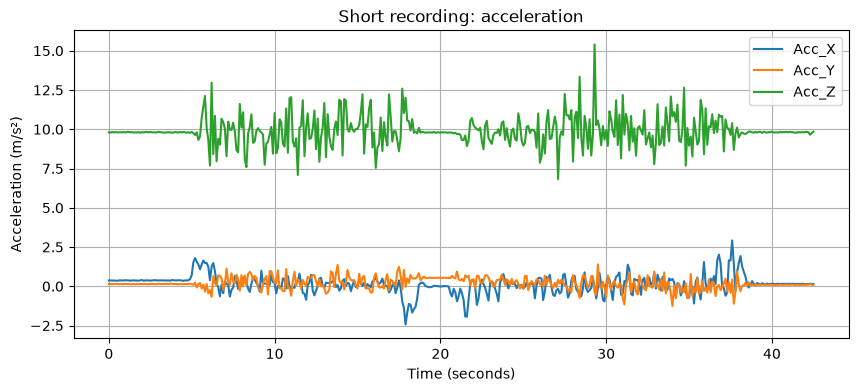

In [3]:
# Plot all three acceleration measurements.
plt.figure(figsize=(10, 4))
plt.plot(short["time_s"], short["Acc_X"], label="Acc_X")
plt.plot(short["time_s"], short["Acc_Y"], label="Acc_Y")
plt.plot(short["time_s"], short["Acc_Z"], label="Acc_Z")
plt.xlabel("Time (seconds)")
plt.ylabel("Acceleration (m/s²)")
plt.title("Short recording: acceleration")
plt.legend()
plt.grid()
plt.show()

## 4. Explore the longer journey

For a ground robot, the most useful gyroscope column for turning is usually **`Gyr_Z`**, which tells us how fast the robot turns around its vertical axis.

- Values near **0**: little turning.
- Large **negative** values: clockwise turning (assuming the sensor's Z axis points up).
- Large **positive** values: counterclockwise turning.

We will also draw `Acc_Z` to see when the robot is vibrating or moving over uneven ground.

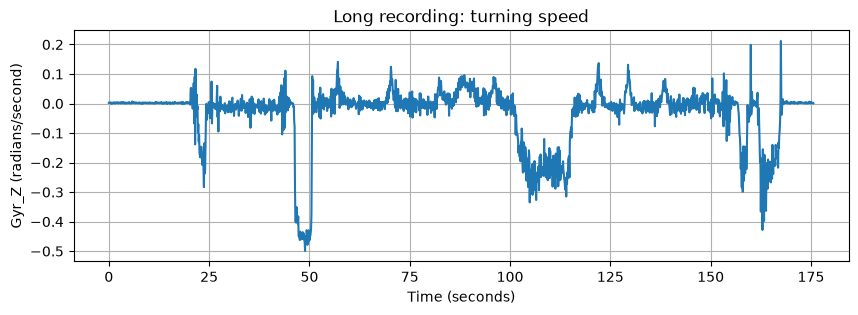

In [9]:
# Graph 1: turning speed.
plt.figure(figsize=(10, 3))
plt.plot(long["time_s"], long["Gyr_Z"])
plt.xlabel("Time (seconds)")
plt.ylabel("Gyr_Z (radians/second)")
plt.title("Long recording: turning speed")
plt.grid()
plt.show()

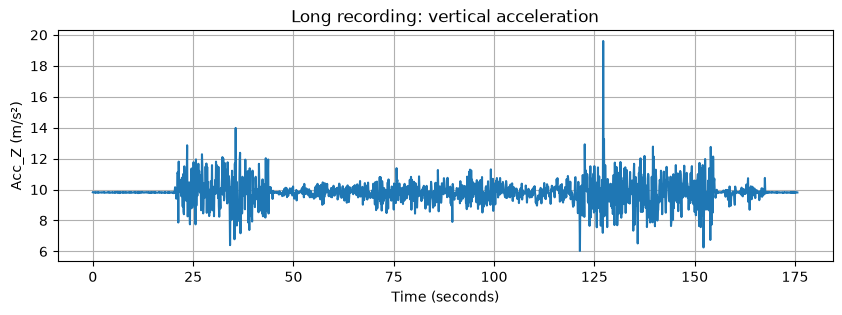

In [10]:
# Graph 2: vertical accelerometer reading.
plt.figure(figsize=(10, 3))
plt.plot(long["time_s"], long["Acc_Z"])
plt.xlabel("Time (seconds)")
plt.ylabel("Acc_Z (m/s²)")
plt.title("Long recording: vertical acceleration")
plt.grid()
plt.show()

## 5. Calculate the robot's heading (direction) - AI

A gyroscope measures **angular velocity** (how quickly something rotates), not the total angle.

We estimate this **bias** using the first 18 seconds, when the robot is still, and subtract it before calculating the heading.

This uses a simple `for` loop to mimic the integration.

Gyroscope bias: 0.002061 rad/s


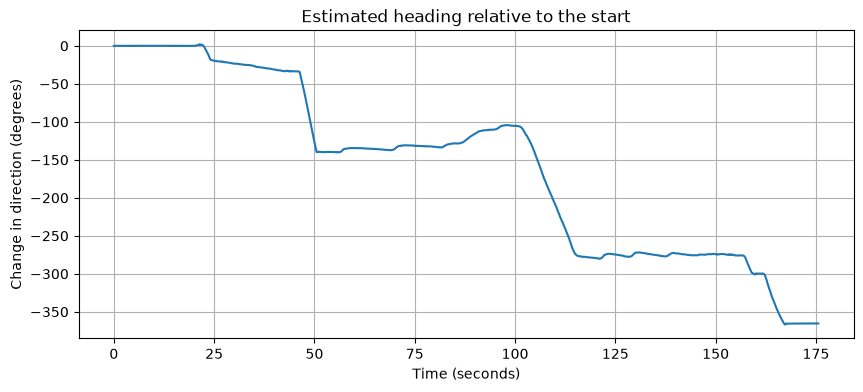

Total rotation: -365.4 degrees


In [5]:
# Convert the two columns into numpy arrays.
time = long["time_s"].to_numpy()
turn_speed = long["Gyr_Z"].to_numpy()

# Average sensor reading during the first 18 seconds (at rest).
bias = long.loc[long["time_s"] < 18, "Gyr_Z"].mean()
print("Gyroscope bias:", round(bias, 6), "rad/s")

# Make an array full of zeroes to store the angle at each time.
heading = np.zeros(len(long))

# Add the little angle turned during each measurement interval.
for i in range(1, len(long)):
    dt = time[i] - time[i - 1]      # Time since previous measurement
    angular_speed = turn_speed[i] - bias
    heading[i] = heading[i - 1] + angular_speed * dt

# np.degrees converts radians into more familiar degrees.
heading_deg = np.degrees(heading)

plt.figure(figsize=(10, 4))
plt.plot(time, heading_deg)
plt.xlabel("Time (seconds)")
plt.ylabel("Change in direction (degrees)")
plt.title("Estimated heading relative to the start")
plt.grid()
plt.show()

print("Total rotation:", round(heading_deg[-1], 1), "degrees")

## 6. Find the important turns - AI

Here are approximate time intervals chosen by looking at the graphs. We can calculate the change in direction for each one.

A change of **−90°** is roughly a right turn; **−180°** is roughly a clockwise U-turn. The exact turn intervals are approximate.

In [6]:
# Each row: start time, end time, description.
stages = [
    (0, 20, "Resting at the beginning"),
    (20, 45, "Starting and curving"),
    (45, 51, "Sharp clockwise turn"),
    (51, 101, "Long middle section"),
    (101, 116, "Large clockwise U-turn"),
    (116, 155, "Another long section"),
    (155, 170, "Final clockwise turn"),
    (170, 175.6, "Stopped at the end")
]

for start, end, description in stages:
    # np.interp finds the estimated heading at a given time.
    angle_start = np.interp(start, time, heading_deg)
    angle_end = np.interp(end, time, heading_deg)
    turn = angle_end - angle_start
    print(f"{start:5.0f}–{end:5.0f} s | {turn:+7.1f}° | {description}")

    0–   20 s |    +0.0° | Resting at the beginning
   20–   45 s |   -33.5° | Starting and curving
   45–   51 s |  -106.1° | Sharp clockwise turn
   51–  101 s |   +33.6° | Long middle section
  101–  116 s |  -171.1° | Large clockwise U-turn
  116–  155 s |    +1.1° | Another long section
  155–  170 s |   -89.6° | Final clockwise turn
  170–  176 s |    +0.1° | Stopped at the end


## 7. Draw a possible route (NOT exact position) - AI

We now know how the robot's **direction** changed. To draw a path, we would also need its speed, but speed was not recorded directly.

For a simple sketch we make two assumptions:

1. The robot moves at **1 arbitrary distance unit per second** from about 20 s to 169 s.
2. It does not move before or after that time.

At each time step, movement is separated into X and Y directions using `cos` and `sin`.

**Do not interpret the axes as metres or compass directions.** The initial direction is simply chosen to be along the positive X axis.

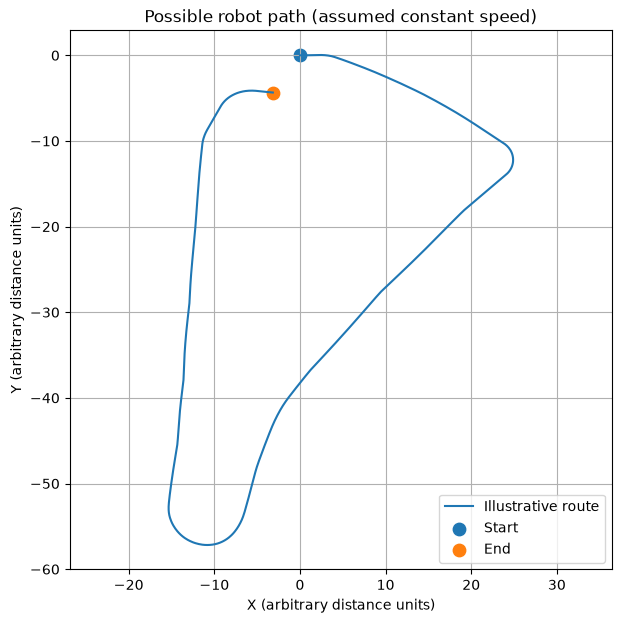

In [7]:
# Our IMAGINED speed: 1 while moving, 0 while stopped.
# This is an assumption, not information measured by the sensor.
speed = np.zeros(len(long))
speed[(time >= 20) & (time < 169)] = 1.0

# Start the path at position (0, 0).
x = np.zeros(len(long))
y = np.zeros(len(long))

# Calculate a new position from the previous position.
for i in range(1, len(long)):
    dt = time[i] - time[i - 1]
    x[i] = x[i - 1] + speed[i - 1] * np.cos(heading[i - 1]) * dt
    y[i] = y[i - 1] + speed[i - 1] * np.sin(heading[i - 1]) * dt

plt.figure(figsize=(7, 7))
plt.plot(x, y, label="Illustrative route")
plt.scatter(x[0], y[0], s=80, label="Start")
plt.scatter(x[-1], y[-1], s=80, label="End")
plt.xlabel("X (arbitrary distance units)")
plt.ylabel("Y (arbitrary distance units)")
plt.title("Possible robot path (assumed constant speed)")
plt.axis("equal")  # Keep the X and Y scales equal.
plt.legend()
plt.grid()
plt.show()

## 8. One more clue: the magnetometer - AI

The magnetometer measures the **local magnetic field**. If measurements at the beginning and end look similar, that is consistent with a similar orientation and environment.

**But:** this alone cannot prove that the robot returned to the exact same position.

In [8]:
# Compare average magnetic measurements near the start and end.
mag_columns = ["Mag_X", "Mag_Y", "Mag_Z"]

start_mag = long.loc[long["time_s"] < 18, mag_columns].mean()
end_mag = long.loc[long["time_s"] > 171, mag_columns].mean()

print("Start magnetic readings:")
print(start_mag.round(3))
print("\nEnd magnetic readings:")
print(end_mag.round(3))

Start magnetic readings:
Mag_X   -0.243
Mag_Y   -0.190
Mag_Z   -1.344
dtype: float64

End magnetic readings:
Mag_X   -0.241
Mag_Y   -0.179
Mag_Z   -1.340
dtype: float64


## 9. What can we conclude?

**From the recorded data:**

- The robot begins and ends with a quiet, approximately stationary interval.
- It makes several clockwise turns, including a sharp turn at about **45–51 s**, a roughly **170° U-turn** at about **101–116 s**, and a roughly **90° final turn** at about **155–170 s**.
- The total change in heading is about **−365°**, close to one complete clockwise revolution. This means its final orientation is approximately its initial orientation.
- Its starting and ending magnetic readings are similar.

**From the *illustrative* path only:**

- If we assume roughly constant speed while it travels, the path looks like an **elongated loop with a U-turn** that comes back near the start.
- We **cannot** recover the exact distances, speed, or geographical route from these measurements alone. Gyroscope errors accumulate, and integrating accelerometer readings twice makes position drift quickly.

I used ai as a supporting tool for this notebook